# 08 · Variable objetivo: ratio real / teórico

Este notebook construye la variable objetivo, el ratio entre el tiempo real efectivo y el tiempo teórico, se estudia cómo se comporta y se localizan valores atípicos.

- **Parte 1.** Construcción y depuración del ratio.
- **Parte 2.** Comportamiento del ratio (análisis exploratorio).

- **Entrada:** `data/processed/df_final.parquet`
- **Salida:** `data/processed/df_entrenamiento.parquet` y figuras en `results/figures/`

In [31]:
import sys
from pathlib import Path

# Raíz del repositorio (la carpeta que contiene src/), para poder importar src
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from scipy import stats

from src.rutas import FIGURES, PROCESSED
from src.limpieza import corte_log

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

BLUE, ORANGE, GRAY = "#2E5EAA", "#D9631E", "#6B7280"  # colores de las figuras

# Parte 1 · Construcción y depuración del ratio

## 1. Variables de tiempo

- `MinutosRealNbr`, `MinutosPreparacionNbr`, `MinutosProduccionNbr`: dato original del MES, tiempo de reloj sin
  corregir por dedicación. Vive a nivel de imputación individual.
- `MinutosReal_total`, `MinutosPreparacion_total`, `MinutosProduccion_total`: suma del tiempo de reloj de todas las
  imputaciones de una misma fase.
- `MinutosReal_efectivo`, `MinutosPreparacion_efectivo`, `MinutosProduccion_efectivo`: tiempo del MES corregido por el
  porcentaje de dedicación (`PorcentajeDedicacionNbr`) a nivel de imputación y después sumado para todas las
  imputaciones de la fase: `MinutosReal_efectivo = MinutosRealNbr × PorcentajeDedicacionNbr / 100`.

Tiempos teóricos del ERP (lo que debería tardar la fase):

- `PreparationTime`: tiempo teórico de preparación.
- `ExecutionTime`: tiempo teórico de ejecución (producción).

In [32]:
df_final = pd.read_parquet(PROCESSED / "df_final.parquet")
print(f"Fases: {len(df_final)}\n")
print("Fases según la unidad de tiempo indicada en el ERP (TimeUnit):")
print(df_final["TimeUnit"].value_counts().to_string())

Fases: 14689

Fases según la unidad de tiempo indicada en el ERP (TimeUnit):
TimeUnit
1.0    14623
2.0       66


Quedan 67 fases con `TimeUnit = 2` y ninguna con `TimeUnit = 3`. Como se comprobó con oficina técnica (notebook 05),
sus tiempos ya están en minutos, así que no se convierte ninguno.

## 2. Construcción del ratio

La variable objetivo es el ratio entre el tiempo real efectivo (MES) y el tiempo teórico previsto por el ERP:

$$\text{ratio} = \frac{\text{tiempo real efectivo}}{\text{tiempo teórico previsto}}$$

Un ratio de 1 indica que la fase duró lo previsto; por encima de 1, que tardó más, y por debajo que tardo menos. Se usa el tiempo total
(preparación + producción) porque la separación entre ambas partes en el MES no es fiable (notebook 07).

In [33]:
df_final["tiempo_real_efectivo"] = df_final["MinutosReal_efectivo"]
df_final["tiempo_previsto"] = df_final["PreparationTime"] + df_final["ExecutionTime"]
df_final["ratio"] = df_final["tiempo_real_efectivo"] / df_final["tiempo_previsto"]

# Comprobaciones
print(f"Fases con tiempo previsto 0 (romperían la división): {(df_final['tiempo_previsto'] == 0).sum()}")
print(f"Fases con tiempo real efectivo 0 (ratio 0, sin señal): {(df_final['tiempo_real_efectivo'] == 0).sum()}\n")
print("Distribución del ratio:")
print(df_final["ratio"].describe().to_string())

Fases con tiempo previsto 0 (romperían la división): 0
Fases con tiempo real efectivo 0 (ratio 0, sin señal): 0

Distribución del ratio:
count    14689.000000
mean         2.032004
std          2.538441
min          0.000114
25%          0.967886
50%          1.464444
75%          2.345238
max        150.616665


En principio no queda ninguna fase con tiempo previsto 0 (se descartaron en el notebook 05) ni con tiempo real efectivo 0. 
Un ratio de 0 no significaría "idoneidad perfecta", sino "sin dato de tiempo real", así que paso el filtro  por seguridad.

In [34]:
antes = len(df_final)
df_final = df_final[df_final["tiempo_real_efectivo"] > 0]
print(f"Descartadas (ratio 0): {antes - len(df_final)} | fases: {len(df_final)}")

Descartadas (ratio 0): 0 | fases: 14689


## 3. Valores atípicos

El máximo, 150,6, es demasiado alto: es físicamente imposible como "mala idoneidad" real. Es ruido residual. Solapamiento que la dedicación no capturó del todo, tiempos teóricos minúsculos mal cargados o algún caso raro. Así mismo con el ratio mínimo de 0,000114.     

Exploración de las dos colas para explorar estos casos:

In [35]:
print("=== Cola alta (tardó mucho más que el teórico) ===")
for umbral in [5, 8, 10, 15, 20]:
    n = (df_final["ratio"] >= umbral).sum()
    print(f"  ratio >= {umbral:>2}: {n:>4} fases ({n / len(df_final):.1%})")

print("\n=== Cola baja (tardó mucho menos que el teórico) ===")
for umbral in [0.5, 0.3, 0.2, 0.1]:
    n = (df_final["ratio"] <= umbral).sum()
    print(f"  ratio <= {umbral}: {n:>4} fases ({n / len(df_final):.1%})")

print("\n=== Percentiles ===")
for p in [0.01, 0.02, 0.05, 0.95, 0.98, 0.99]:
    print(f"  P{int(p * 100):>2}: {df_final['ratio'].quantile(p):.3f}")

=== Cola alta (tardó mucho más que el teórico) ===
  ratio >=  5:  798 fases (5.4%)
  ratio >=  8:  259 fases (1.8%)
  ratio >= 10:  152 fases (1.0%)
  ratio >= 15:   63 fases (0.4%)
  ratio >= 20:   32 fases (0.2%)

=== Cola baja (tardó mucho menos que el teórico) ===
  ratio <= 0.5:  882 fases (6.0%)
  ratio <= 0.3:  402 fases (2.7%)
  ratio <= 0.2:  259 fases (1.8%)
  ratio <= 0.1:  158 fases (1.1%)

=== Percentiles ===
  P 1: 0.091
  P 2: 0.229
  P 5: 0.448
  P95: 5.209
  P98: 7.515
  P99: 10.231


El ratio es una magnitud multiplicativa: expresa cuántas veces el tiempo real excede o queda por debajo del teórico.  

Para descartar las colas se calcula un corte de valores atípicos aplicado sobre el logaritmo del ratio, donde la distribución resulta simétrica en torno a 0. Sobre log(ratio) se calcula el rango intercuartílico (IQR) y se definen como atípicos los valores fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR]. Deshaciendo la transformación logarítmica, esto define un intervalo de valores admisibles de forma aproximada.

> **¡¡IMPORTANTE!!**: durante el transcurso del trabajo se ha detectado que aplicar este corte a las colas para el conjunto total de datos implica DATALEAKAGE. Es por esto que en este notebook solo se formaliza de forma exploratoria, y en `10_split_temporal` se aplicará de forma correcta, calculando los límites solo en los datos de entrenamiento.   

In [36]:
# calcular los umbrales
UMBRAL_BAJO, UMBRAL_ALTO = corte_log(df_final)

Umbrales: 0.257 (bajo) y 8.846 (alto)


Antes de aplicar el corte se estudia qué fases caen en cada cola, para comprobar que son errores de registro y no
comportamientos reales. Para cada cola se mira:

- cuántas fases tienen solo 2 imputaciones y cuánto tiempo real registran;
- si el fenómeno es estable en el tiempo (tasa mensual);
- si se concentra en algunas máquinas o líneas de artículo.

In [37]:
def analizar_cola(df, mascara_cola, nombre):
    """Describe las fases de una cola del ratio (patrón de registro, estabilidad y concentración)."""
    cola = df[mascara_cola]
    minimas = cola[cola["n_imputaciones"] == 2]  # fases con solo 2 imputaciones

    print(f"Fases en la cola {nombre}: {len(cola)}")
    print(f"  con 2 imputaciones: {len(minimas)} ({len(minimas) / len(cola):.1%})")
    print(f"  (en todo el dataset, fases con 2 imputaciones: {(df['n_imputaciones'] == 2).mean():.1%}; "
          f"media de imputaciones fuera de la cola: {df.loc[~mascara_cola, 'n_imputaciones'].mean():.2f})")
    print(f"\nTiempo real efectivo de las fases con 2 imputaciones (min):")
    print(minimas["tiempo_real_efectivo"].describe().round(2).to_string())
    print(f"Mediana de la dedicación media: {minimas['dedicacion_media'].median()}")

    # Estabilidad en el tiempo: % de fases de cada mes que caen en la cola con 2 imputaciones
    tasa_mensual = (minimas["fecha_fase"].dt.to_period("M").value_counts().sort_index()
                    / df["fecha_fase"].dt.to_period("M").value_counts().sort_index() * 100).round(2)
    print(f"\nTasa mensual (%): media {tasa_mensual.mean():.2f}, desviación típica {tasa_mensual.std():.2f}")
    print(tasa_mensual.to_string())

    # Concentración por máquina y por línea de artículo
    fases_maquina = df["MaquinaDominante"].value_counts()
    por_maquina = pd.DataFrame({
        "fases en la cola": cola["MaquinaDominante"].value_counts(),
        "% de la cola": (cola["MaquinaDominante"].value_counts(normalize=True) * 100).round(1),
        "con 2 imputaciones": minimas["MaquinaDominante"].value_counts(),
    }).fillna(0)
    por_maquina["% de las fases de la máquina (2 imp.)"] = (
        por_maquina["con 2 imputaciones"] / fases_maquina.reindex(por_maquina.index) * 100).round(2)
    por_maquina = por_maquina.sort_values("fases en la cola", ascending=False)

    lineas_cola = cola["Nombre Línea"].fillna("(sin línea)")
    lineas_minimas = minimas["Nombre Línea"].fillna("(sin línea)")
    por_linea = pd.DataFrame({
        "fases en la cola": lineas_cola.value_counts(),
        "% de la cola": (lineas_cola.value_counts(normalize=True) * 100).round(1),
        "con 2 imputaciones": lineas_minimas.value_counts(),
        "% de las de 2 imp.": (lineas_minimas.value_counts(normalize=True) * 100).round(1),
    }).fillna(0).sort_values("fases en la cola", ascending=False)

    print("\nPor máquina:")
    display(por_maquina.head(10))
    print("Por línea de artículo:")
    display(por_linea.head(6))

### 3.1 Cola baja

In [38]:
analizar_cola(df_final, df_final["ratio"] < UMBRAL_BAJO, "baja")

Fases en la cola baja: 329
  con 2 imputaciones: 282 (85.7%)
  (en todo el dataset, fases con 2 imputaciones: 73.9%; media de imputaciones fuera de la cola: 2.51)

Tiempo real efectivo de las fases con 2 imputaciones (min):
count    282.00
mean      16.73
std       32.06
min        0.03
25%        0.45
50%        3.95
75%       17.18
max      239.37
Mediana de la dedicación media: 50.0

Tasa mensual (%): media 1.85, desviación típica 0.59
fecha_fase
2025-06    1.32
2025-07    3.08
2025-08    1.75
2025-09    1.59
2025-10    2.36
2025-11    1.91
2025-12    1.36
2026-01    1.26
2026-02    1.17
2026-03    2.64
2026-04    2.32
2026-05    2.24
2026-06    1.29
2026-07    1.57
Freq: M

Por máquina:


,fases en la cola,% de la cola,con 2 imputaciones,% de las fases de la máquina (2 imp.)
MaquinaDominante,,,,
TP02,77,23.4,69,2.16
PH04,52,15.8,40,22.86
CM14,25,7.6,20,2.82
CM05,24,7.3,20,2.20
TN05,18,5.5,17,4.02
TP01,17,5.2,17,4.11
TN09,13,4.0,12,0.37
CM15,11,3.3,8,9.30
TN10,11,3.3,11,2.18


Por línea de artículo:


,fases en la cola,% de la cola,con 2 imputaciones,% de las de 2 imp.
Nombre Línea,,,,
Portalectrodes,103,31.3,98.0,34.8
Braços,90,27.4,76.0,27.0
Conductor Rígid,64,19.5,48.0,17.0
Electrodes,17,5.2,16.0,5.7
(sin línea),13,4.0,13.0,4.6
Nivells Inferiors Torns,8,2.4,8.0,2.8


Estos errores se mantienen a lo largo del año y aparecen en la mayoría de las máquinas: por la forma en que se dan,
apuntan a ruido sistemático. Hay fases que no se contemplan a la hora de imputar tiempos: los operarios las abren para
marcar la cantidad producida y después las cierran, sin tener en cuenta el registro de tiempo. Por eso registran
tiempos tan bajos y deben eliminarse.

### 3.2 Cola alta

In [39]:
analizar_cola(df_final, df_final["ratio"] > UMBRAL_ALTO, "alta")

Fases en la cola alta: 201
  con 2 imputaciones: 118 (58.7%)
  (en todo el dataset, fases con 2 imputaciones: 73.9%; media de imputaciones fuera de la cola: 2.49)

Tiempo real efectivo de las fases con 2 imputaciones (min):
count    118.00
mean     173.68
std       88.95
min       49.50
25%      112.04
50%      146.36
75%      212.67
max      465.08
Mediana de la dedicación media: 50.0

Tasa mensual (%): media 0.81, desviación típica 0.39
fecha_fase
2025-06    1.76
2025-07    1.21
2025-08    0.82
2025-09    0.56
2025-10    0.81
2025-11    0.83
2025-12    1.15
2026-01    0.88
2026-02    0.29
2026-03    0.71
2026-04    0.58
2026-05    0.70
2026-06    0.21
2026-07    0.79
Freq: M

Por máquina:


,fases en la cola,% de la cola,con 2 imputaciones,% de las fases de la máquina (2 imp.)
MaquinaDominante,,,,
TP02,81,40.3,54.0,1.69
TN09,65,32.3,35.0,1.09
TP01,18,9.0,14.0,3.38
CM06,9,4.5,6.0,0.47
TN08,6,3.0,2.0,0.36
CM16,4,2.0,3.0,0.50
CM12,3,1.5,2.0,0.46
PH04,3,1.5,1.0,0.57
TN04,3,1.5,0.0,0.00


Por línea de artículo:


,fases en la cola,% de la cola,con 2 imputaciones,% de las de 2 imp.
Nombre Línea,,,,
Portalectrodes,177,88.1,110.0,93.2
Braços,10,5.0,4.0,3.4
Conductor Rígid,4,2.0,3.0,2.5
Varis Torn,3,1.5,1.0,0.8
Plaques,2,1.0,0.0,0.0
Electrodes,2,1.0,0.0,0.0


En la cola alta predominan unas máquinas (TP02 y TN09) y una línea de artículos (Portalectrodes). Se analiza esa
combinación:

In [40]:
mask_combo = df_final["MaquinaDominante"].isin(["TP02", "TN09"]) & (df_final["Nombre Línea"] == "Portalectrodes")
combo, resto = df_final[mask_combo], df_final[~mask_combo]

print(f"Fases de la combinación TP02/TN09 + Portalectrodes: {len(combo)}\n")
print("Ratio por máquina dentro de la combinación:")
print(combo.groupby("MaquinaDominante")["ratio"].describe().round(3).to_string())
print(f"\nRatio mediano de la combinación: {combo['ratio'].median():.3f} | resto del dataset: {resto['ratio'].median():.3f}")
print(f"Fases que superan el umbral alto en la combinación: {(combo['ratio'] > UMBRAL_ALTO).mean():.2%}")
print(f"Fases que superan el umbral alto en el resto: {(resto['ratio'] > UMBRAL_ALTO).mean():.2%}")

Fases de la combinación TP02/TN09 + Portalectrodes: 5296

Ratio por máquina dentro de la combinación:
                   count   mean    std    min    25%    50%    75%     max
MaquinaDominante                                                          
TN09              3123.0  2.544  2.565  0.003  1.206  1.878  3.080  67.988
TP02              2173.0  2.654  3.203  0.008  1.135  1.773  3.103  72.340

Ratio mediano de la combinación: 1.833 | resto del dataset: 1.312
Fases que superan el umbral alto en la combinación: 2.53%
Fases que superan el umbral alto en el resto: 0.71%


### 3.3 Conclusión de las colas

Los valores de ratio anómalamente bajos se concentran en fases con 2 imputaciones (el 85,2 %, frente al 73,5 % del conjunto de fases) y con un tiempo real registrado muy reducido (mediana de 4 minutos): un patrón compatible con un registro administrativo incompleto más que con una producción real anormalmente rápida. Se mantiene estable durante todo el periodo del dataset, sin picos ni tendencia, y se concentra de forma desigual por máquina (en PH04 afecta al 22,86 % de sus fases, frente a menos del 10 % en el resto de máquinas, salvo MA02, que tiene una sola fase) y por artículo (Portalectrodes y Braços acumulan más del 60 % de los casos). El personal de la planta de producción confirma el hallazgo.
           
En la cola alta la concentración es aún más extrema: 2 máquinas (TP02 y TN09) explican el 72,7 % de los casos y una única línea de artículos, Portalectrodes, el 87,8 %. Esto no encaja con ruido disperso, sino con una combinación máquina-artículo estructuralmente más lenta: sus fases ya presentan un ratio mediano superior al resto del dataset (1,83 frente a 1,31). Aun así, dentro de esa misma combinación el percentil 75 del ratio se sitúa en torno a 3 (lejos del umbral de 8,8) y solo el 2,59 % de sus fases lo superan, por lo que el corte no elimina esa tendencia real —que
queda representada en el grueso de casos retenidos— sino solo su extremo minoritario y atípico incluso dentro de su propio proceso. Se mantiene, por tanto, el mismo criterio de corte para la cola alta.

### 3.4 Aplicación del corte

> EL CORTE NO DEBE APLICARSE → EVITAR DATALEAKAGE

In [41]:
# antes = len(df_final)
# alta = (df_final["ratio"] >= UMBRAL_ALTO).sum()
# baja = (df_final["ratio"] <= UMBRAL_BAJO).sum()

# df_corte = df_final[(df_final["ratio"] > UMBRAL_BAJO) & (df_final["ratio"] < UMBRAL_ALTO)]

# print(f"Descartadas en la cola alta (>= {UMBRAL_ALTO}): {alta}")
# print(f"Descartadas en la cola baja (<= {UMBRAL_BAJO}): {baja}")
# print(f"Fases: {antes} → {len(df_corte)}\n")
# print("Distribución del ratio tras el corte:")
# print(df_corte["ratio"].describe().to_string())

### 3.5 Figuras del corte

In [42]:
# GRAFICO CON RATIO VS LOG(RATIO)
# log_ratio = np.log(df_final["ratio"])
# fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

# ax = axes[0]
# ax.hist(df_final["ratio"].clip(upper=15), bins=60, color=BLUE, alpha=0.85, edgecolor="white", linewidth=0.3)
# for u in (UMBRAL_BAJO, UMBRAL_ALTO):
#     ax.axvline(u, color=ORANGE, linewidth=1.6, linestyle="--")
# ax.set_title("Ratio (escala original)", fontsize=12, fontweight="bold", loc="left")
# ax.set_xlabel("ratio"); ax.set_ylabel("nº de fases"); ax.set_xlim(0, 15)

# ax2 = axes[1]
# ax2.hist(log_ratio, bins=60, color=BLUE, alpha=0.85, edgecolor="white", linewidth=0.3)
# ax2.axvline(0, color=GRAY, linewidth=1.2, linestyle=":")
# for u in (UMBRAL_BAJO, UMBRAL_ALTO):
#     ax2.axvline(np.log(u), color=ORANGE, linewidth=1.6, linestyle="--")
# ax2.set_title("log(ratio)", fontsize=12, fontweight="bold", loc="left")
# ax2.set_xlabel("log(ratio)"); ax2.set_ylabel("nº de fases")

# for a in axes:
#     a.spines[["top", "right"]].set_visible(False)
# fig.legend(handles=[Line2D([0], [0], color=ORANGE, lw=1.6, linestyle="--",
#                            label=f"Umbrales de corte ({UMBRAL_BAJO} / {UMBRAL_ALTO})")],
#            loc="lower center", frameon=False, bbox_to_anchor=(0.5, -0.02), fontsize=9)
# fig.suptitle("Distribución del ratio: escala original frente a logarítmica", fontsize=13, fontweight="bold", y=1.02)
# plt.tight_layout()
# plt.savefig(FIGURES / "08_ratio_vs_log_ratio.png", dpi=200, bbox_inches="tight")
# plt.show()

In [43]:
# GRAFICO CON RATIO ANTES Y DESPUES DEL CORTE
# fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

# ax = axes[0]
# ax.hist(df_final["ratio"].clip(upper=15), bins=60, color=GRAY, alpha=0.85, edgecolor="white", linewidth=0.3)
# for u in (UMBRAL_BAJO, UMBRAL_ALTO):
#     ax.axvline(u, color=ORANGE, linewidth=1.6, linestyle="--")
# ax.set_title(f"Antes del corte (n = {len(df_final):,})".replace(",", "."), fontsize=12, fontweight="bold", loc="left")

# ax2 = axes[1]
# ax2.hist(df_corte["ratio"], bins=60, color=BLUE, alpha=0.85, edgecolor="white", linewidth=0.3)
# ax2.set_title(f"Después del corte (n = {len(df_corte):,})".replace(",", "."), fontsize=12, fontweight="bold", loc="left")

# for a in axes:
#     a.set_xlabel("ratio"); a.set_ylabel("nº de fases"); a.set_xlim(0, 15)
#     a.spines[["top", "right"]].set_visible(False)
# fig.legend(handles=[Line2D([0], [0], color=ORANGE, lw=1.6, linestyle="--",
#                            label=f"Umbrales de corte ({UMBRAL_BAJO} / {UMBRAL_ALTO})")],
#            loc="lower center", frameon=False, bbox_to_anchor=(0.5, -0.02), fontsize=9)
# fig.suptitle("Distribución del ratio antes y después de eliminar valores atípicos", fontsize=13, fontweight="bold", y=1.02)
# plt.tight_layout()
# plt.savefig(FIGURES / "08_corte_antes_despues.png", dpi=200, bbox_inches="tight")
# plt.show()

## 4. Dataset de entrenamiento

Se eliminan las columnas de tiempos intermedios (incluidas las que solo se conocen tras ejecutar la fase, como
`dedicacion_media` y `n_imputaciones`), `TimeUnit` y los identificadores internos, y se ordenan las columnas.

In [44]:
df_entrenamiento = df_final.drop(columns=[
    # columnas de tiempos y de registro
    "MinutosPreparacion_efectivo", "MinutosProduccion_efectivo", "MinutosReal_efectivo",
    "MinutosReal_total", "MinutosPreparacion_total", "MinutosProduccion_total",
    "dedicacion_media", "n_imputaciones", "TimeUnit", "ManualStartDate", "RealEndDate",
    "PreparationTime", "ExecutionTime",
    # identificadores internos
    "IDMaquina", "IDGrupo", "IDManufacturingOrder", "MESEntityId", "SmFaseUid",
])

df_entrenamiento = df_entrenamiento[[
    "fecha_fase", "IDMOTask", "smOrdenId", "smOrdenNme", "smFaseNme", "Description", "IDUsualTask",
    "MaquinaDominante", "NombreMaquina", "CodigoGrupo", "NombreGrupo",
    "smMaterialId", "Descripción Artículo", "CodProductLine", "Nombre Línea", "CodProductFamily", "Nombre Família",
    "ProductEntry", "MaterialExit", "Quantity",
    "tiempo_real_efectivo", "tiempo_previsto", "ratio",
]]

df_entrenamiento.to_parquet(PROCESSED / "df_entrenamiento.parquet")
print(df_entrenamiento.shape)
df_entrenamiento.head(3)

(14689, 23)


,fecha_fase,IDMOTask,smOrdenId,smOrdenNme,smFaseNme,Description,IDUsualTask,MaquinaDominante,NombreMaquina,CodigoGrupo,NombreGrupo,smMaterialId,Descripción Artículo,CodProductLine,Nombre Línea,CodProductFamily,Nombre Família,ProductEntry,MaterialExit,Quantity,tiempo_real_efectivo,tiempo_previsto,ratio
0,2025-10-02 03:12:05.010,ee76d685-a4cc-47d4-b418-6e33d2ae2921,OF2509545,Portacápsulas F704501049704(150713),TPP,Mecanitzat al Torn Puma Petit,29783995-2f56-48be-9664-461e6f0b402a,TN09,TPP DOOSAN PUMA 240 (TPP) Torn C.N.C,TPU,Torns Puma (Taller COURES),PE1JNCX0012,Elektrodenaufnamhe F704501049704(DS086228),P,Portalectrodes,PE,Portalectrodes,0.0,0.0,3.0,41.76667,21.0,1.988889
1,2025-10-21 12:26:43.433,3c6cccb8-2326-4d66-9714-b09ac436be82,OF2510311,ELECTRODO SUP PERNO 097625004020,TMO,Mecanització al TMO,e7285597-98fb-4216-aa59-b4775f4f7cfa,TN10,MORI SEIKI NL2500/1250 Torn C.N.C,TCN,Torns Control Numèric,ELEXA2X0340,ELECTRODO SUP PERNO 097625004020(W9EESELE021),E,Electrodes,ELE,Electrode,0.0,0.0,5.0,41.31667,50.0,0.826333
2,2026-01-23 09:40:53.233,91871d20-4755-4ab9-a993-2cb6d76f1aed,OF2600009,Sonderpinole 5658644,TPG-CNY,Mecanitzar al TMO,2562d1e9-8157-4c9e-aff1-b77b7a7e2868,TN05,MORI SEIKI NL2500 Torn C.N.C MORI SEIKI NL2500,TCN,Torns Control Numèric,BR0XA2X0058,Sonderpinole 5658644,B,Braços,BR,Braços rodons,0.0,0.0,1.0,12.33334,55.0,0.224243


# Parte 2 · Comportamiento del ratio

Para las figuras se traducen al castellano los nombres de las familias de máquinas (solo en una copia; el dataset
guardado no cambia).

In [45]:
nombres_familia = {
    "Centres de Mecanitzat Vertical ALUMINIS": "Centros Mecanizado Vertical Aluminio",
    "Premses Conformats": "Prensas Conformado",
    "Centres de Mecanitzat Horitzontal COURES": "Centros Mecanizado Horizontal Cobre",
    "Centres de Mecanitzat Vertical COURES": "Centros Mecanizado Vertical Cobre",
    "Torns Control Numèric": "Tornos Control Numérico",
    "Màquines de Taladrat Profund": "Máquinas Taladrado Profundo",
    "Centre de Mecanitzat 5 Eixos petites": "Centros de Mecanizado 5 Ejes",
    "Màquines Secció Flexibles": "Máquinas Sección Flexible",
    "Torns Puma (Taller COURES)": "Tornos Puma Cobre",
}

eda = df_entrenamiento.copy()
eda["NombreGrupo"] = eda["NombreGrupo"].replace(nombres_familia)
eda["Nombre Família"] = eda["Nombre Família"].fillna("(sin família)")


def boxplot_ratio(datos, columna, titulo, archivo, alto_por_grupo=None):
    """Tabla de estadísticos del ratio por grupo y diagrama de cajas horizontal (sin atípicos)."""
    tabla = datos.groupby(columna)["ratio"].agg(n="count", media="mean", mediana="median", desv_est="std")
    tabla = tabla.sort_values("media", ascending=False)
    orden = tabla.index.tolist()
    alto = 5 if alto_por_grupo is None else max(5, len(orden) * alto_por_grupo)

    fig, ax = plt.subplots(figsize=(10, alto))
    bp = ax.boxplot([datos.loc[datos[columna] == g, "ratio"] for g in orden], orientation="horizontal",
                    tick_labels=orden, patch_artist=True, showfliers=False)
    for patch in bp["boxes"]:
        patch.set_facecolor(BLUE); patch.set_alpha(0.7)
    ax.axvline(1, color=GRAY, linestyle=":", linewidth=1.2)
    ax.set_xlabel("ratio")
    ax.set_title(titulo, fontsize=12, fontweight="bold", loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.savefig(FIGURES / archivo, dpi=200, bbox_inches="tight")
    plt.show()
    return tabla.round(3)

## 5. Ratio por familia de máquina

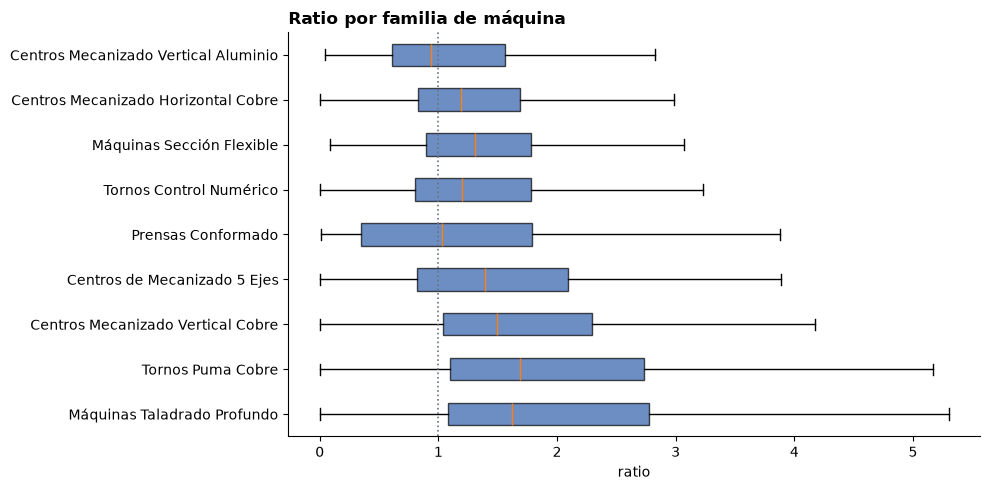

,n,media,mediana,desv_est
NombreGrupo,,,,
Máquinas Taladrado Profundo,3602,2.442,1.622,2.990
Tornos Puma Cobre,4088,2.313,1.685,2.393
Centros Mecanizado Vertical Cobre,2633,1.954,1.492,3.269
Centros de Mecanizado 5 Ejes,547,1.757,1.393,1.868
Prensas Conformado,314,1.598,1.028,2.555
Tornos Control Numérico,1609,1.506,1.197,1.293
Máquinas Sección Flexible,171,1.401,1.309,0.697
Centros Mecanizado Horizontal Cobre,1236,1.399,1.187,1.046
Centros Mecanizado Vertical Aluminio,489,1.219,0.934,0.978


In [46]:
boxplot_ratio(eda, "NombreGrupo", "Ratio por familia de máquina", "08_ratio_por_familia_maquina.png")

## 6. Ratio por familia de artículo

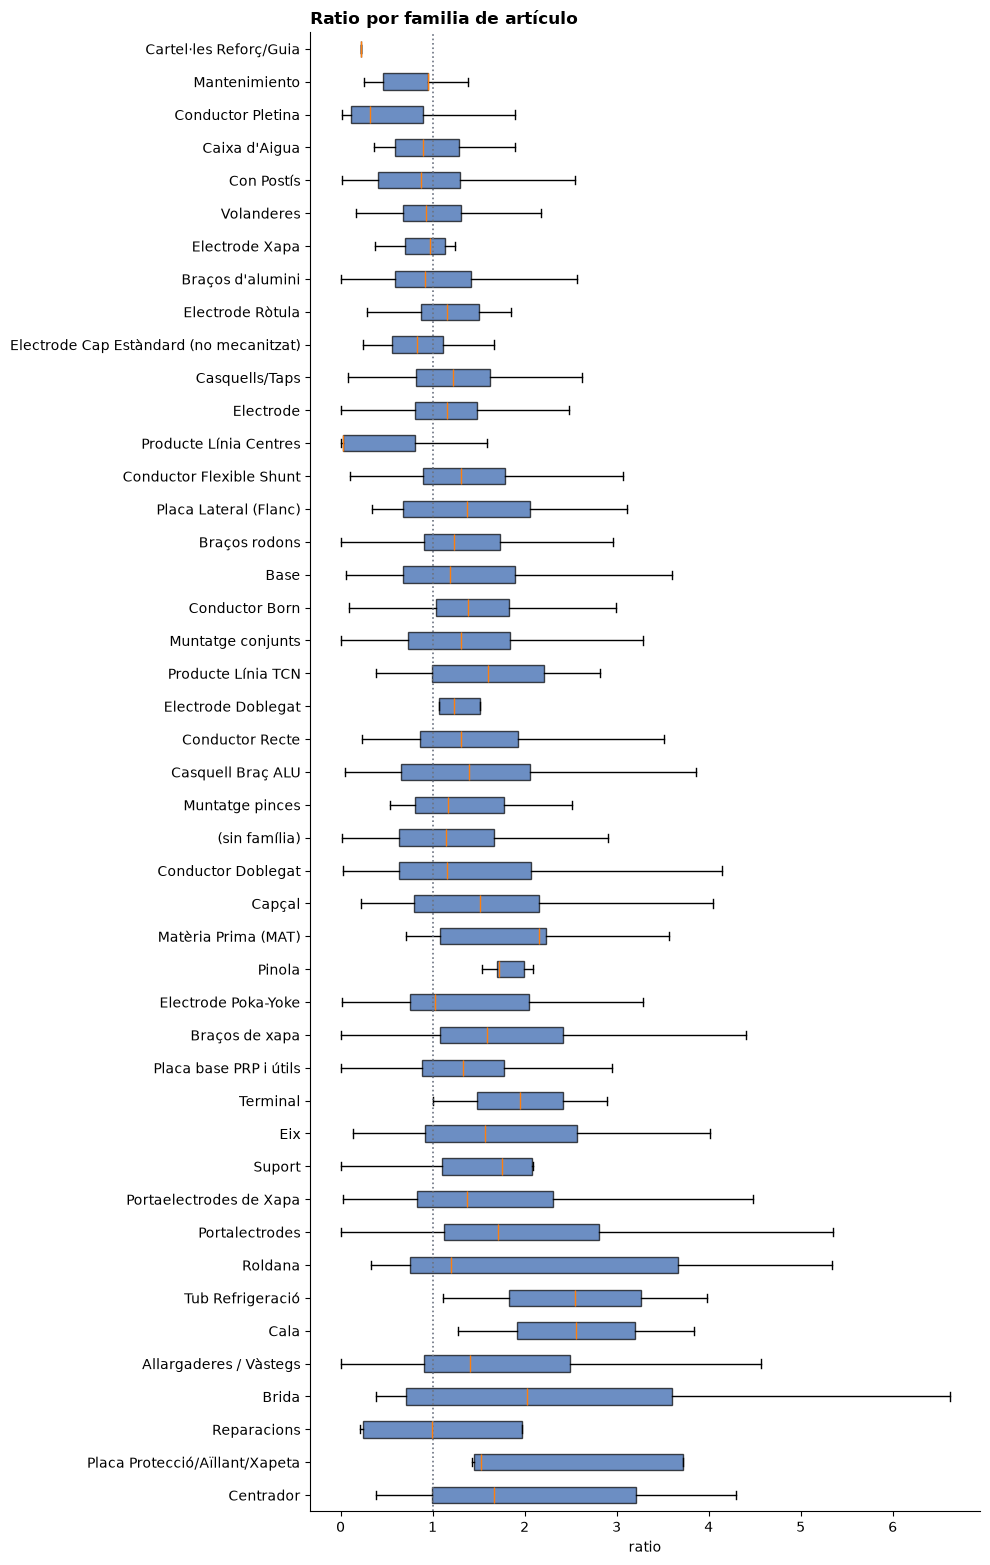

,n,media,mediana,desv_est
Nombre Família,,,,
Centrador,10,16.668,1.669,47.082
Placa Protecció/Aïllant/Xapeta,5,3.502,1.522,3.428
Reparacions,9,3.137,0.990,4.957
Brida,8,2.887,2.023,2.898
Allargaderes / Vàstegs,209,2.749,1.411,4.398
Cala,2,2.553,2.553,1.813
Tub Refrigeració,2,2.546,2.546,2.026
Roldana,16,2.463,1.205,2.640
Portalectrodes,8201,2.372,1.715,2.547


In [47]:
boxplot_ratio(eda, "Nombre Família", "Ratio por familia de artículo", "08_ratio_por_familia_articulo.png",
              alto_por_grupo=0.35)

## 7. Ratio según la duración prevista de la fase

Las fases se reparten en cinco grupos del mismo tamaño según su tiempo previsto. Para cada grupo se calcula el ratio
mediano, el porcentaje de fases en la cola (el 10 % de ratios más altos) y la desviación mediana en minutos
(tiempo real − tiempo previsto).

In [48]:
umbral_cola = eda["ratio"].quantile(0.90)  # el 10 % de ratios más altos
grupos = pd.qcut(eda["tiempo_previsto"], q=5)
desv_minutos = eda["tiempo_real_efectivo"] - eda["tiempo_previsto"]

por_duracion = pd.DataFrame({"grupo_duracion": grupos, "ratio": eda["ratio"], "desv_minutos": desv_minutos}) \
    .groupby("grupo_duracion", observed=True).agg(
        fases=("ratio", "size"),
        ratio_mediano=("ratio", "median"),
        pct_en_cola=("ratio", lambda r: (r > umbral_cola).mean() * 100),
        desv_mediana_min=("desv_minutos", "median"),
    ).round(2)

print(f"Umbral de la cola (percentil 90 del ratio): {umbral_cola:.2f}")
por_duracion

Umbral de la cola (percentil 90 del ratio): 3.86


,fases,ratio_mediano,pct_en_cola,desv_mediana_min
grupo_duracion,,,,
"(1.999, 15.0]",3214,2.06,23.77,12.49
"(15.0, 30.0]",2806,1.75,13.76,16.22
"(30.0, 60.0]",2816,1.50,7.71,22.44
"(60.0, 108.0]",2971,1.32,3.10,26.23
"(108.0, 9060.0]",2882,1.10,0.35,16.46


Se aprecia un patrón claro: a medida que aumenta la duración de la fase, su ratio se estabiliza hacia 1. Las fases que
requieren menos tiempo concentran los ratios más altos: el 22,4 % de las fases cortas (5–15 min) pertenecen a la cola,
más del doble del 10 % esperado.

A su vez, las fases cortas son las que menos se desvían en minutos. Esto refleja la sensibilidad del ratio, que
magnifica las desviaciones de las fases cortas: buena parte de la cola del ratio la forman fases cortas con
desviaciones pequeñas en minutos.

**Precauciones**

- En la evaluación: si solo se mira el error en ratio, las fases cortas dominarán la imagen, y un modelo podría
  parecer malo solo por fallar en fases cortas. Por eso el error se reporta también por tramo de duración y en minutos
  (notebook 15).
- El ruido de registro podría pesar más en las fases cortas: un pequeño error al imputar en el MES altera mucho su
  ratio, así que es probable que acumulen los errores más grandes en ratio.

El ratio varía más en las fases cortas que en las largas, lo que puede ser una limitación del trabajo.

## 8. Evolución mensual del ratio

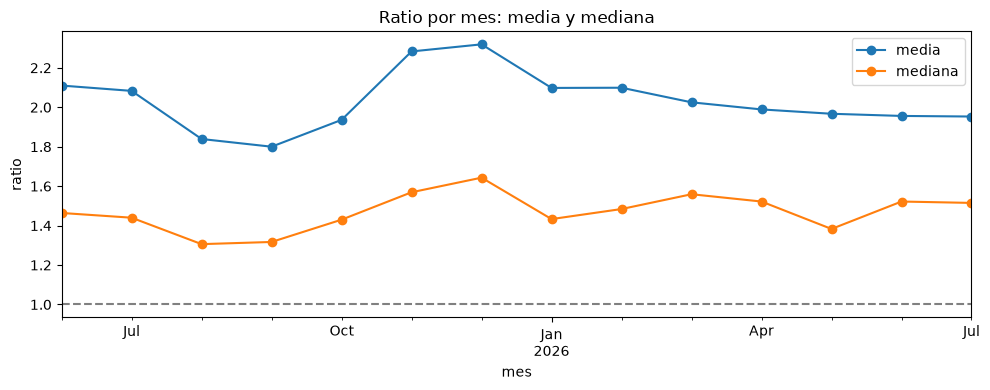

,fases,media,mediana
mes,,,
2025-06,680,2.110,1.464
2025-07,1657,2.083,1.440
2025-08,973,1.839,1.306
2025-09,1257,1.800,1.317
2025-10,1358,1.936,1.430
2025-11,1203,2.283,1.569
2025-12,953,2.319,1.643
2026-01,1028,2.098,1.433
2026-02,1022,2.099,1.484


In [49]:
ratio_mes = (eda.assign(mes=eda["fecha_fase"].dt.to_period("M"))
             .groupby("mes")["ratio"].agg(fases="size", media="mean", mediana="median").round(3))

ax = ratio_mes[["media", "mediana"]].plot(marker="o", figsize=(10, 4), title="Ratio por mes: media y mediana")
ax.axhline(1, color="gray", ls="--")  # referencia: el ERP acierta
ax.set_ylabel("ratio")
plt.tight_layout()
plt.savefig(FIGURES / "08_ratio_por_mes.png", dpi=200, bbox_inches="tight")
plt.show()
ratio_mes

No se aprecia un patrón temporal claro ni cambios de nivel marcados a simple vista. El ratio se mantiene por encima de 1 todos los meses, así que el sesgo es persistente. La media y la mediana se mueven casi en paralelo: la asimetría es estable en el tiempo.
     
Hay variación entre meses. Los valores más bajos aparecen en agosto y septiembre de 2025 y el más alto en diciembre de 2025. Los meses de febrero a abril de 2026, que se usan como validación (notebook 10), se sitúan en la parte alta, por encima de varios meses de entrenamiento.

## Resumen

In [50]:
print(f"Umbrales del corte para todo el dataset (exploratorio): {UMBRAL_BAJO} – {UMBRAL_ALTO}\n")
print("-" * 60)
print("Recuento de datos:")
print("-" * 60)
print(f"Órdenes de fabricación: {df_entrenamiento['smOrdenId'].nunique()}")
print(f"Fases de fabricación:   {df_entrenamiento['IDMOTask'].nunique()}")
print(f"Tipos de fase:          {df_entrenamiento['smFaseNme'].nunique()}")
print(f"Artículos:              {df_entrenamiento['smMaterialId'].nunique()}")
print(f"Líneas de artículos:    {df_entrenamiento['Nombre Línea'].nunique()}")
print(f"Familias de artículos:  {df_entrenamiento['Nombre Família'].nunique()}")
print(f"Familias de máquinas:   {df_entrenamiento['CodigoGrupo'].nunique()}")
print(f"Máquinas:               {df_entrenamiento['MaquinaDominante'].nunique()}")
print("-" * 60)

Umbrales del corte para todo el dataset (exploratorio): 0.257 – 8.846

------------------------------------------------------------
Recuento de datos:
------------------------------------------------------------
Órdenes de fabricación: 6501
Fases de fabricación:   14689
Tipos de fase:          38
Artículos:              3939
Líneas de artículos:    17
Familias de artículos:  44
Familias de máquinas:   9
Máquinas:               28
------------------------------------------------------------


Visualizar el ratio vs log(ratio)

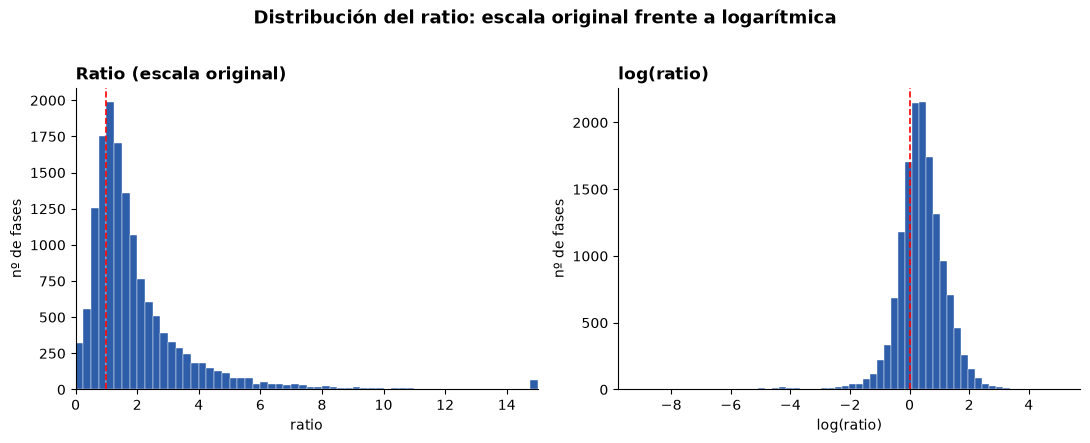

In [51]:
# GRAFICO CON RATIO VS LOG(RATIO)
log_ratio = np.log(df_entrenamiento["ratio"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

ax = axes[0]
ax.hist(df_entrenamiento["ratio"].clip(upper=15), bins=60, color=BLUE, alpha=1, edgecolor="white", linewidth=0.3)

ax.set_title("Ratio (escala original)", fontsize=12, fontweight="bold", loc="left")
ax.set_xlabel("ratio"); ax.set_ylabel("nº de fases"); ax.set_xlim(0, 15)
ax.axvline(1, color="red", linestyle="--", linewidth=1.2)

ax2 = axes[1]
ax2.hist(log_ratio, bins=60, color=BLUE, alpha=1, edgecolor="white", linewidth=0.3)
ax2.axvline(0, color="red", linestyle="--", linewidth=1.2)

ax2.set_title("log(ratio)", fontsize=12, fontweight="bold", loc="left")
ax2.set_xlabel("log(ratio)"); ax2.set_ylabel("nº de fases")

for a in axes:
    a.spines[["top", "right"]].set_visible(False)

fig.suptitle("Distribución del ratio: escala original frente a logarítmica", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES / "08_ratio_vs_log_ratio.png", dpi=200, bbox_inches="tight")
plt.show()